# 02. Baseline analysis

Validation results for the three Phase 1 baselines. Metrics in this notebook are validation metrics. The test partition is not scored.

In [1]:
import json
from pathlib import Path
import sys

import joblib
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

metrics = pd.read_csv(ROOT / "results" / "tables" / "validation_metrics.csv")
status = json.loads((ROOT / "results" / "test_set_status.json").read_text())
display(metrics.loc[:, ["display_name", "roc_auc", "f1", "precision", "recall", "balanced_accuracy"]])
print("test_metrics_computed =", status["test_metrics_computed"])
print("test_predictions_computed =", status["test_predictions_computed"])
assert status["test_metrics_computed"] is False
assert status["test_predictions_computed"] is False

,display_name,roc_auc,f1,precision,recall,balanced_accuracy
0,Logistic Regression,0.908120,0.656240,0.744928,0.586423,0.761631
1,Random Forest,0.919669,0.683627,0.798172,0.597832,0.775141
2,XGBoost,0.931336,0.722414,0.804622,0.655448,0.802693


test_metrics_computed = False
test_predictions_computed = False


logistic_regression: steps=['preprocess', 'classifier']
random_forest: steps=['preprocess', 'classifier']


xgboost: steps=['preprocess', 'classifier']


**roc_curves.png**

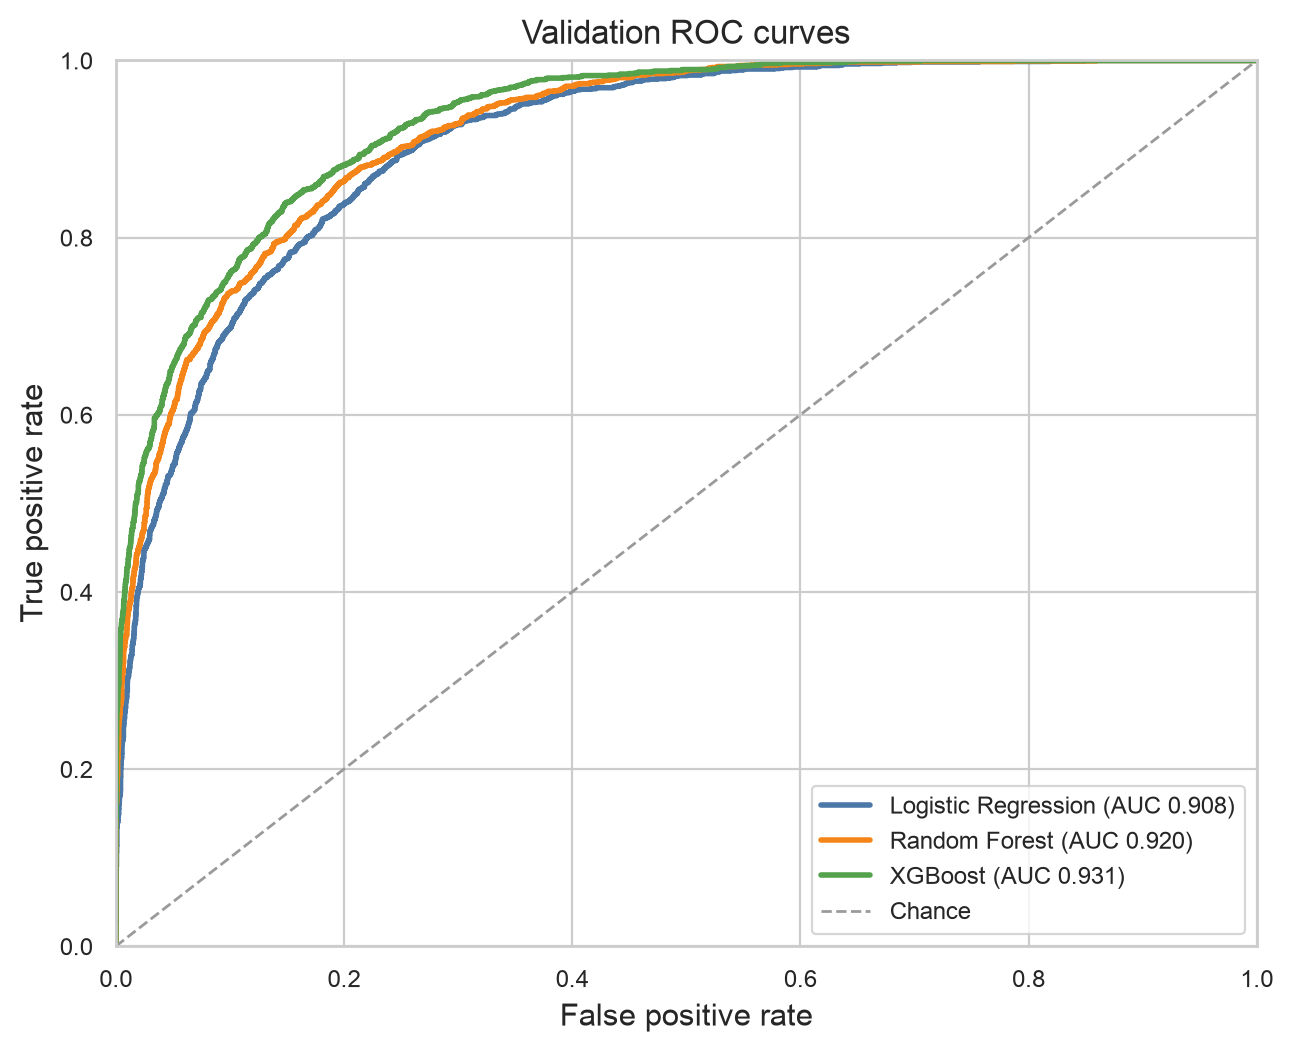

**confusion_matrices.png**

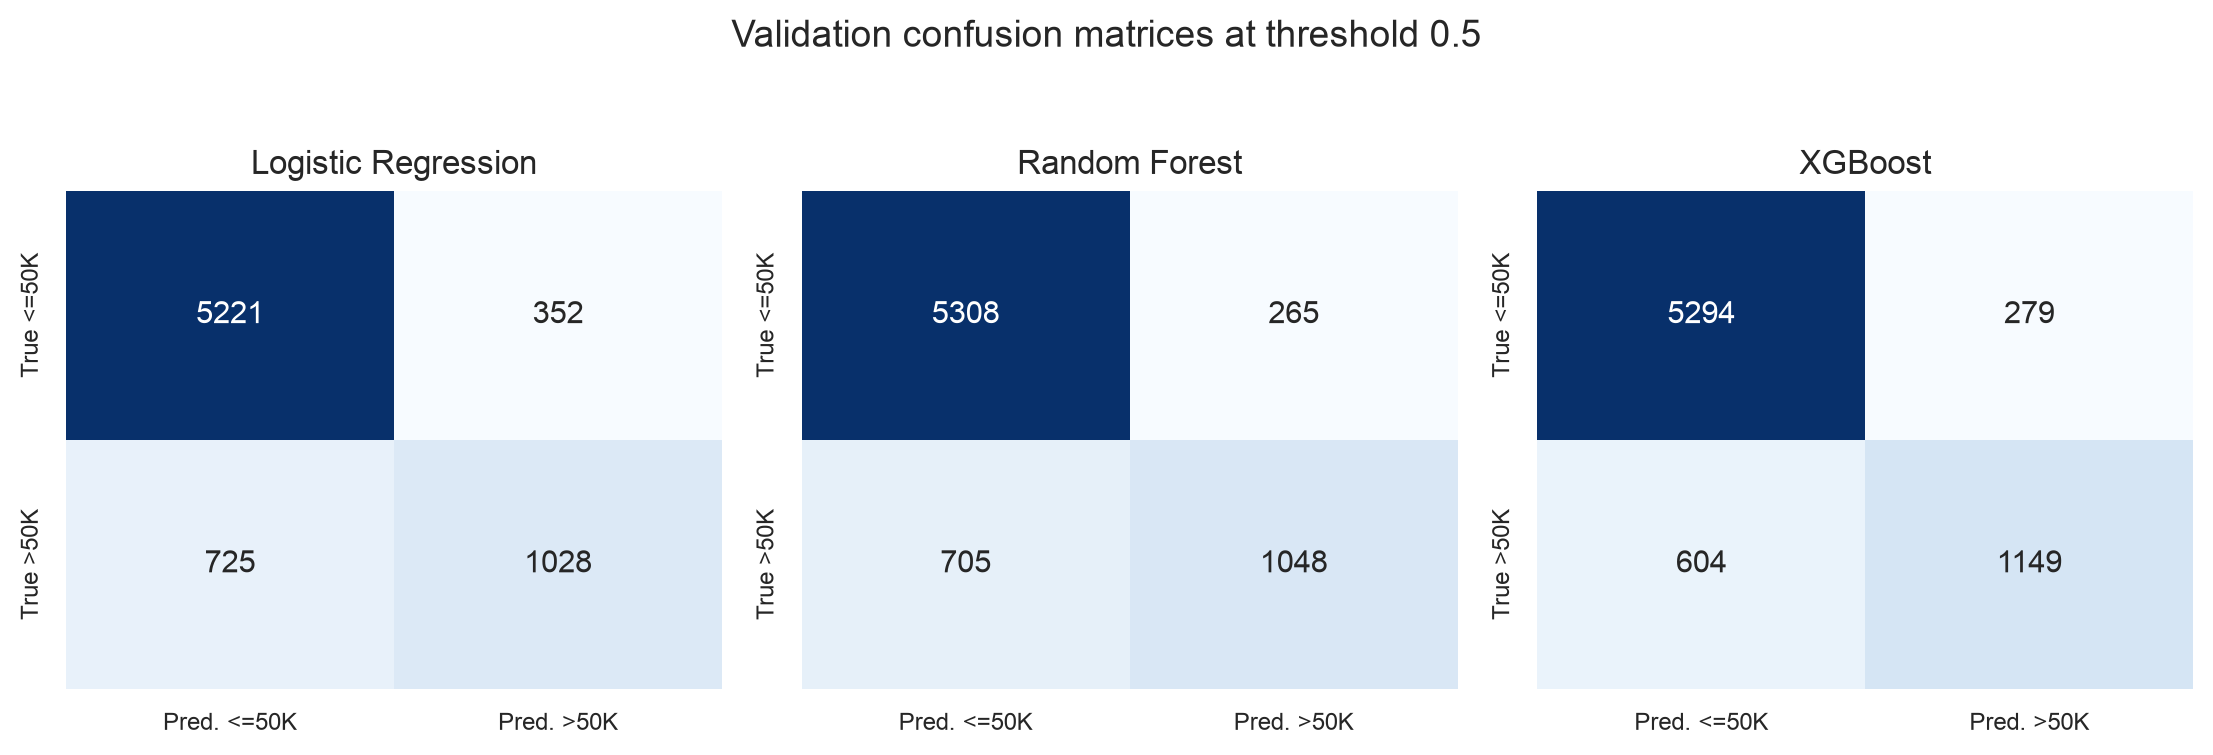

**model_comparison.png**

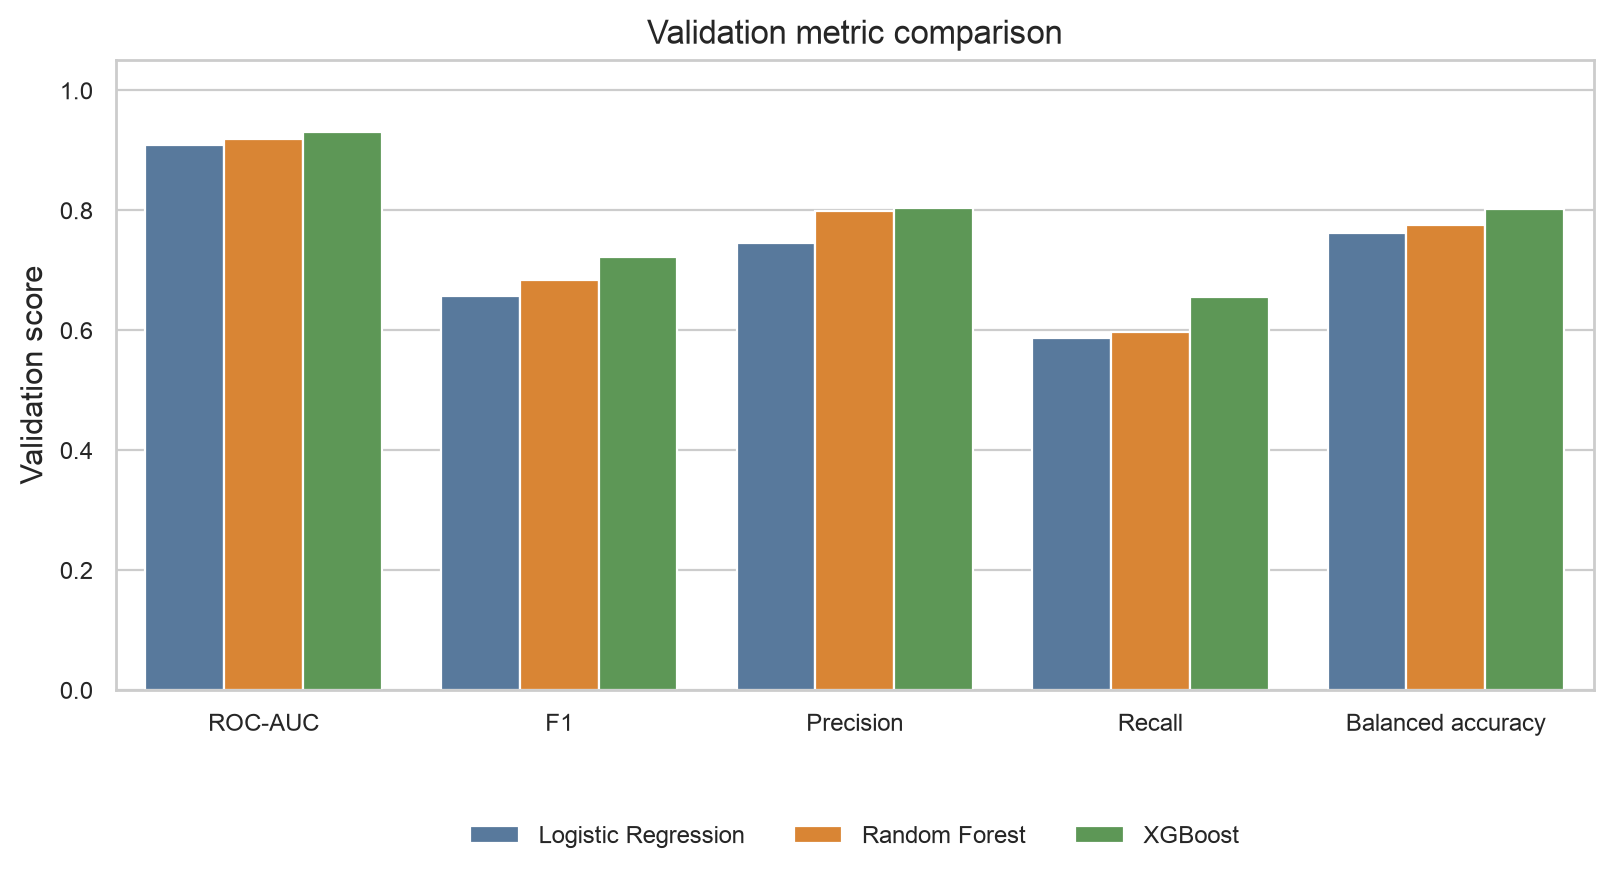

In [2]:
for name in ("logistic_regression", "random_forest", "xgboost"):
    pipeline = joblib.load(ROOT / "models" / f"{name}.joblib")
    assert isinstance(pipeline, Pipeline)
    steps = [step for step, _ in pipeline.steps]
    print(f"{name}: steps={steps}")

for name in ("roc_curves.png", "confusion_matrices.png", "model_comparison.png"):
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(ROOT / "results" / "figures" / name)))